In [1]:
import pandas as pd
from statsbombpy import sb
df=sb.events(match_id=3869685)

C:\Users\vivek\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsbombpy\api_client.py:21: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


In [2]:
df.columns


Index(['50_50', 'bad_behaviour_card', 'ball_receipt_outcome',
       'ball_recovery_offensive', 'ball_recovery_recovery_failure',
       'block_deflection', 'block_offensive', 'carry_end_location',
       'clearance_aerial_won', 'clearance_body_part', 'clearance_head',
       'clearance_left_foot', 'clearance_other', 'clearance_right_foot',
       'counterpress', 'dribble_nutmeg', 'dribble_outcome', 'dribble_overrun',
       'duel_outcome', 'duel_type', 'duration', 'foul_committed_advantage',
       'foul_committed_card', 'foul_committed_offensive',
       'foul_committed_penalty', 'foul_committed_type', 'foul_won_advantage',
       'foul_won_defensive', 'foul_won_penalty', 'goalkeeper_body_part',
       'goalkeeper_end_location', 'goalkeeper_outcome', 'goalkeeper_position',
       'goalkeeper_technique', 'goalkeeper_type', 'id', 'index',
       'interception_outcome', 'location', 'match_id', 'minute', 'off_camera',
       'out', 'pass_aerial_won', 'pass_angle', 'pass_assisted_shot_id'

In [18]:
print(df.player.value_counts())

player
Enzo Fernandez                     328
Rodrigo Javier De Paul             242
Lionel Andrés Messi Cuccittini     242
Nicolás Hernán Otamendi            215
Jules Koundé                       211
Aurélien Djani Tchouaméni          205
Cristian Gabriel Romero            203
Dayotchanculle Upamecano           198
Alexis Mac Allister                196
Raphaël Varane                     182
Adrien Rabiot                      176
Nicolás Alejandro Tagliafico       165
Julián Álvarez                     150
Kylian Mbappé Lottin               149
Theo Bernard François Hernández    145
Nahuel Molina Lucero               142
Ángel Fabián Di María Hernández    132
Randal Kolo Muani                  127
Marcus Thuram                      119
Marcos Javier Acuña                112
Antoine Griezmann                  103
Hugo Lloris                         97
Kingsley Coman                      85
Damián Emiliano Martínez            83
Eduardo Camavinga                   83
Gonzalo Ariel Mont

In [19]:
df=df[(df['player']=='Lionel Andrés Messi Cuccittini') & (df['type']=='Pass')]

In [20]:
df=df[['location','pass_end_location','pass_outcome']]

In [21]:
df.head()

,location,pass_end_location,pass_outcome
36,"[76.6, 35.7]","[116.2, 8.9]",Complete
39,"[99.3, 57.3]","[96.7, 49.8]",Complete
52,"[67.9, 59.0]","[49.0, 60.3]",Complete
62,"[81.8, 65.2]","[70.2, 67.7]",Complete
103,"[39.2, 48.1]","[65.3, 35.4]",Complete


In [22]:
df[['x','y']]=df['location'].apply(pd.Series)

In [23]:
df[['end_x','end_y']]=df['pass_end_location'].apply(pd.Series)

In [24]:
df['pass_outcome']=df['pass_outcome'].fillna("Complete")

In [25]:
df.head()

,location,pass_end_location,pass_outcome,x,y,end_x,end_y
36,"[76.6, 35.7]","[116.2, 8.9]",Complete,76.6,35.7,116.2,8.9
39,"[99.3, 57.3]","[96.7, 49.8]",Complete,99.3,57.3,96.7,49.8
52,"[67.9, 59.0]","[49.0, 60.3]",Complete,67.9,59.0,49.0,60.3
62,"[81.8, 65.2]","[70.2, 67.7]",Complete,81.8,65.2,70.2,67.7
103,"[39.2, 48.1]","[65.3, 35.4]",Complete,39.2,48.1,65.3,35.4


In [26]:
df['final_third_passes']=(df['end_x']>=80)&(df['x']<80)

In [28]:
df.final_third_passes.value_counts()

final_third_passes
False    52
True      8
Name: count, dtype: int64

In [29]:
df=df[df['final_third_passes']==True]

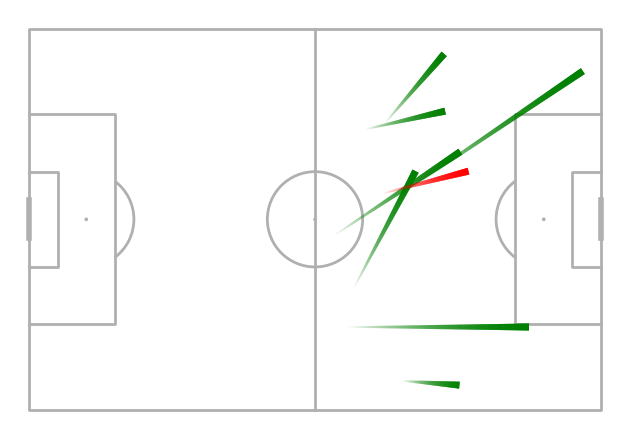

In [32]:
from mplsoccer import Pitch 
pitch=Pitch(pitch_type='statsbomb')
fig,ax=pitch.draw()
for x in df.to_dict(orient='records'):
    if x['pass_outcome']=="Complete":
        pitch.lines(x['x'], x['y'], x['end_x'], x['end_y'], lw=5, transparent=True,comet=True,ax=ax,color='g')
    else:
        pitch.lines(x['x'],x['y'],x['end_x'],x['end_y'],lw=5,transparent=True,comet=True,ax=ax,color='r')